# Annotation des verbatims JDMA par LLM (5 dimensions émotionnelles)

Ce notebook annote `data/verbatim_2026_07_31.csv` avec le prompt de `prompt-LLM.rtf` et quatre LLM open-weights,
puis compare leurs annotations (accord inter-modèles, consensus, lien avec les Z-scores de l'analyse factorielle).

**Organisation**
- L'inférence tourne dans `annotate_llm.py` : **un processus vLLM par modèle, chacun sur son propre GPU H100**.
  Les modèles (22–27B en bf16, ~45–55 Go) tiennent chacun sur une H100 NVL de 94 Go, le reste sert au cache KV.
  Avec 2 GPU libres, les 4 modèles passent en 2 vagues ; avec 4 GPU libres, en une seule.
- Le noyau du notebook n'importe **ni torch ni vLLM** : il ne réserve aucune mémoire GPU et la VRAM est rendue à la fin de chaque processus.
- **Décodage contraint par schéma JSON** (exactement 5 clés, entiers 0–3), **température 0**, « thinking » désactivé (Qwen, Gemma).
- **Reprise sur erreur** : sauvegarde par blocs dans `data/annotations/<RUN_NAME>/<slug>.csv` ; une relance ne traite que les textes manquants.
- Les processus survivent à une interruption du noyau ; leurs journaux sont dans `data/annotations/<RUN_NAME>/logs/`.

**Prérequis** : vLLM dans un environnement séparé (son torch est incompatible avec celui du projet) :
```bash
uv venv ~/venvs/vllm --python 3.12
uv pip install --python ~/venvs/vllm/bin/python vllm pandas
```
Le notebook tourne avec le noyau habituel du projet ; seul `annotate_llm.py` utilise `~/venvs/vllm`.

## Imports et configuration

In [8]:
import json
import os
import signal
import subprocess
import sys
import time
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output, display
from sklearn.metrics import cohen_kappa_score

from annotate_llm import DIMENSIONS, build_messages, parse_scores  # n'importe pas vLLM

In [26]:
# ---------------------------------------------------------------- Paramètres
DATA_PATH = Path("../data/verbatim_2026_07_31.csv")
ZSCORES_PATH = Path("../data/Zscores_dimensions.csv")
WORKER = Path("annotate_llm.py").resolve()
WORKER_PYTHON = Path("~/venvs/vllm/bin/python").expanduser()   # environnement dédié à vLLM
HF_HOME = Path("../cache/").resolve()   # même cache que model_trainer.ipynb

# Pilote d'abord : N_SAMPLE textes tirés au hasard (mêmes textes pour les 4 modèles).
# Mettre N_SAMPLE = None pour annoter tout le corpus.
N_SAMPLE = 10000
SEED = 1234
RUN_NAME = f"pilot_{N_SAMPLE}" if N_SAMPLE else "full"
OUT_DIR = Path("../data/annotations") / RUN_NAME
LOG_DIR = OUT_DIR / "logs"
JOB_DIR = OUT_DIR / "jobs"
for d in (OUT_DIR, LOG_DIR, JOB_DIR):
    d.mkdir(parents=True, exist_ok=True)

# GPU utilisables (index nvidia-smi). Le GPU 1 est utilisé par un autre utilisateur.
# Un GPU de la liste qui n'a pas MIN_FREE_GB de libre est ignoré au lancement.
GPUS = [0, 2, 3]
MIN_FREE_GB = 80             # un GPU avec moins de mémoire libre n'est pas utilisé

CONFIG = {
    "chunk_size": 500,               # textes entre deux sauvegardes
    "max_model_len": 8192,           # le texte le plus long fait ~8 000 caractères (~2 500 tokens)
    "max_new_tokens": 96,            # le JSON de réponse fait ~40 tokens
    "gpu_memory_utilization": 0.90,  # part de la VRAM du GPU réservée par vLLM
    "seed": SEED,
}

MODELS = [
    {
        "id": "google/gemma-4-26B-A4B-it",
        "slug": "gemma4_26b_a4b",
        "multimodal": True,
    },
    {
        "id": "mistralai/Mistral-Small-3.2-24B-Instruct-2506",
        "slug": "mistral_small_3_2_24b",
        "multimodal": True,
    },
    {
        "id": "Qwen/Qwen3.6-27B",
        "slug": "qwen3_6_27b",
        "multimodal": True,
    },
    {
        "id": "utter-project/EuroLLM-22B-Instruct-2512",
        "slug": "eurollm_22b_instruct_2512",
        "multimodal": False,
    },
]

# Options vLLM propres à certains modèles (fusionnées avec les options par défaut du script)
VLLM_EXTRA_KWARGS = {
    "mistral_small_3_2_24b": {   # format recommandé par Mistral pour vLLM
        "tokenizer_mode": "mistral",
        "config_format": "mistral",
        "load_format": "mistral",
    },
    "qwen3_6_27b": {             # Qwen accepte aussi la vidéo : on coupe les deux modalités
        "limit_mm_per_prompt": {"image": 0, "video": 0},
        "max_num_seqs": 512,     # modèle hybride Mamba : au plus 586 séquences en parallèle sur une H100
    },
}

# Arguments du chat template : désactive le « thinking » (Qwen3.x, Gemma 4).
# Mistral (tokenizer mistral_common) n'a pas de template Jinja -> None.
DEFAULT_CHAT_TEMPLATE_KWARGS = {"enable_thinking": False}
CHAT_TEMPLATE_KWARGS = {"mistral_small_3_2_24b": None}

## Prompt d'annotation

Repris de `prompt-LLM.rtf`. Le texte à annoter est ajouté à la fin, entre balises `<texte>`.
Le prompt est enregistré avec le run : on ne peut pas mélanger deux versions du prompt dans un même `RUN_NAME`.

In [27]:
PROMPT_ANNOTATION = """Ce [texte] est la narration d'une expérience vécue avec une administration. Utilise uniquement le texte fourni. Pour chaque texte, attribue indépendamment un score entier de 0 à 3 à chacune des cinq dimensions suivantes.

Satisfaction : appréciation positive d’une expérience dans laquelle l’usager peut avancer, atteindre son objectif ou surmonter une difficulté. Comprend le contentement, la joie, la gratitude, la confiance, l’apaisement et le soulagement. Une appréciation comme « tout s’est bien passé » suffit à en indiquer la présence ; un résultat favorable décrit sans appréciation ne suffit pas.

Contestation : colère, indignation ou sentiment d’injustice face à un traitement jugé inacceptable et imputé à un acteur. L’usager considère généralement qu’une autre conduite était possible ou qu’une correction est due. La cible peut être l’administration ou un tiers impliqué dans l’expérience. Un désaccord ou un recours purement factuel ne suffit pas.

Désillusion : déception et affaiblissement de la confiance dans une résolution ou dans l’utilité des efforts engagés. Comprend le découragement, le sentiment d’abandon, l’impuissance, le désespoir, la résignation et le renoncement lorsqu’ils expriment une perte d’espoir. Une déception explicite suffit à en indiquer la présence, sans exiger un renoncement.

Détresse : inquiétude, anxiété ou angoisse face à une conséquence redoutée dont l’issue reste incertaine. L’usager craint ce qui pourrait lui arriver. Distingue cette menace encore ouverte de la perte d’espoir propre à la désillusion. Une situation grave ou urgente ne suffit pas sans expression d’inquiétude.

Perplexité : étonnement, surprise, confusion ou doute devant une situation inattendue ou difficile à interpréter. L’usager ne comprend pas ce qui se passe, ce qui est demandé ou comment poursuivre. L’incertitude concerne la compréhension, tandis que la détresse concerne les conséquences redoutées. La perplexité peut être positive, négative ou neutre. Une simple demande d’information ne suffit pas.

Applique ce barème à chaque dimension :
0 = non exprimée : aucun indice textuel suffisant.
1 = faible : expression légère ou atténuée.
2 = modérée : expression nette, sans marque de forte intensité.
3 = forte : expression très intense.
Mesure l’intensité exprimée, pas ta certitude ni la gravité objective des faits. « Je suis un peu inquiet » correspond à une détresse de 1 ; « je suis angoissé » à 2 ; « cette angoisse m’empêche de dormir » à 3.

Plusieurs dimensions peuvent coexister, y compris satisfaction et émotions négatives. Tous les scores peuvent être nuls. Ne transforme pas automatiquement un obstacle, un comportement ou une insatisfaction générale en émotion particulière.
Prends en compte toute l’expérience racontée, y compris les émotions passées. Pour chaque dimension, retiens l’intensité la plus élevée clairement exprimée. Une résolution heureuse n’efface pas une inquiétude antérieure. Ne compte pas une émotion niée ou seulement hypothétique.
Réponds uniquement avec un objet JSON valide contenant exactement les clés suivantes et des valeurs entières de 0 à 3 :
{"satisfaction": 0, "contestation": 0, "desillusion": 0, "detresse": 0, "perplexite": 0}
"""

PROMPT_PATH = OUT_DIR / "prompt.txt"
if PROMPT_PATH.exists() and PROMPT_PATH.read_text(encoding="utf-8") != PROMPT_ANNOTATION:
    raise ValueError(f"Le prompt a changé depuis le début du run {RUN_NAME!r} : changer RUN_NAME.")
PROMPT_PATH.write_text(PROMPT_ANNOTATION, encoding="utf-8")

print(build_messages(PROMPT_ANNOTATION, "Exemple de verbatim.")[0]["content"][-300:])

mpte pas une émotion niée ou seulement hypothétique.
Réponds uniquement avec un objet JSON valide contenant exactement les clés suivantes et des valeurs entières de 0 à 3 :
{"satisfaction": 0, "contestation": 0, "desillusion": 0, "detresse": 0, "perplexite": 0}

<texte>
Exemple de verbatim.
</texte>


## Données

In [28]:
verbatim_df = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig")
verbatim_df = verbatim_df.rename(columns={"ID expérience": "id_experience"})
print("Lignes :", len(verbatim_df))

verbatim_df = verbatim_df.drop_duplicates("id_experience")
print("Après dédoublonnage des ID :", len(verbatim_df))

verbatim_df["full_comment"] = (
    verbatim_df["Titre"].fillna("").str.strip()
    + "\n\n"
    + verbatim_df["Description"].fillna("").str.strip()
).str.strip()
verbatim_df = verbatim_df[verbatim_df["full_comment"].str.len() > 0]

CORPUS_PATH = OUT_DIR / "corpus.csv"
if CORPUS_PATH.exists():   # on garde exactement le même échantillon d'une session à l'autre
    corpus_df = pd.read_csv(CORPUS_PATH, dtype={"full_comment": str})
else:
    corpus_df = verbatim_df.sample(n=N_SAMPLE, random_state=SEED) if N_SAMPLE else verbatim_df
    corpus_df = corpus_df[["id_experience", "full_comment"]].reset_index(drop=True)
    corpus_df.to_csv(CORPUS_PATH, index=False)
print("Textes à annoter :", len(corpus_df))
corpus_df["full_comment"].str.len().describe()

Lignes : 160983
Après dédoublonnage des ID : 160962
Textes à annoter : 10000


count    10000.000000
mean       574.471200
std        420.203479
min         42.000000
25%        266.750000
50%        454.000000
75%        747.000000
max       3995.000000
Name: full_comment, dtype: float64

In [29]:
assert parse_scores('{"satisfaction": 0, "contestation": 2, "desillusion": 1, "detresse": 0, "perplexite": 3}')["parse_ok"]
assert not parse_scores("pas de json")["parse_ok"]
assert not parse_scores('{"satisfaction": 5}')["parse_ok"]

## Lancement des annotations (un processus par GPU)

In [30]:
def output_path(model: dict) -> Path:
    return OUT_DIR / f"{model['slug']}.csv"


def n_done(model: dict) -> int:
    path = output_path(model)
    if not path.exists():
        return 0
    return pd.read_csv(path, usecols=["id_experience"])["id_experience"].nunique()


def is_complete(model: dict) -> bool:
    return n_done(model) >= len(corpus_df)


def worker_pid(model: dict):
    """PID du processus d'annotation s'il tourne encore (y compris lancé avant un redémarrage du noyau)."""
    pid_file = LOG_DIR / f"{model['slug']}.pid"
    if not pid_file.exists():
        return None
    pid = int(pid_file.read_text())
    try:
        os.kill(pid, 0)
    except OSError:
        return None
    return pid


def gpu_status() -> pd.DataFrame:
    out = subprocess.run(
        ["nvidia-smi", "--query-gpu=index,name,memory.used,memory.total,utilization.gpu",
         "--format=csv,noheader,nounits"],
        capture_output=True, text=True, check=True,
    ).stdout
    rows = [[x.strip() for x in line.split(",")] for line in out.strip().splitlines()]
    df = pd.DataFrame(rows, columns=["gpu", "name", "used_mib", "total_mib", "util_%"])
    df[["gpu", "used_mib", "total_mib"]] = df[["gpu", "used_mib", "total_mib"]].astype(int)
    df["free_gb"] = ((df["total_mib"] - df["used_mib"]) / 1024).round(1)
    return df.set_index("gpu")


def launch(model: dict, gpu: int) -> subprocess.Popen:
    job = {
        "model": model,
        "config": CONFIG,
        "vllm_kwargs": VLLM_EXTRA_KWARGS.get(model["slug"], {}),
        "chat_template_kwargs": CHAT_TEMPLATE_KWARGS.get(model["slug"], DEFAULT_CHAT_TEMPLATE_KWARGS),
        "corpus": str(CORPUS_PATH.resolve()),
        "prompt": str(PROMPT_PATH.resolve()),
        "output": str(output_path(model).resolve()),
    }
    job_path = JOB_DIR / f"{model['slug']}.json"
    job_path.write_text(json.dumps(job, ensure_ascii=False, indent=2), encoding="utf-8")

    env = {
        **os.environ,
        "CUDA_VISIBLE_DEVICES": str(gpu),
        "HF_HOME": str(HF_HOME),
        "TOKENIZERS_PARALLELISM": "false",
        "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    }
    log = open(LOG_DIR / f"{model['slug']}.log", "a")
    log.write(f"\n===== {time.strftime('%Y-%m-%d %H:%M:%S')} — lancement sur GPU {gpu}\n")
    log.flush()
    proc = subprocess.Popen(
        [str(WORKER_PYTHON), str(WORKER), "--job", str(job_path.resolve())],
        stdout=log, stderr=subprocess.STDOUT, env=env,
        start_new_session=True,   # survit à une interruption / un redémarrage du noyau
    )
    (LOG_DIR / f"{model['slug']}.pid").write_text(str(proc.pid))
    return proc


def last_log_line(model: dict) -> str:
    path = LOG_DIR / f"{model['slug']}.log"
    if not path.exists():
        return ""
    lines = [l for l in path.read_text(errors="replace").splitlines() if l.strip()]
    return lines[-1][:140] if lines else ""


def show_progress(assigned: dict | None = None) -> None:
    assigned = assigned or {}
    display(pd.DataFrame([{
        "modèle": m["slug"],
        "GPU": assigned.get(m["slug"], ""),
        "en cours": worker_pid(m) is not None,
        "annotés": n_done(m),
        "total": len(corpus_df),
        "%": round(100 * n_done(m) / len(corpus_df), 1),
        "dernière ligne du journal": last_log_line(m),
    } for m in MODELS]).set_index("modèle"))


def stop_all() -> None:
    """Arrête tous les processus d'annotation de ce run."""
    for m in MODELS:
        pid = worker_pid(m)
        if pid:
            os.killpg(os.getpgid(pid), signal.SIGTERM)
            print(f"Arrêt de {m['slug']} (pid {pid})")

In [31]:
status = gpu_status()
display(status)
usable_gpus = [g for g in GPUS if status.loc[g, "free_gb"] >= MIN_FREE_GB]
print("GPU utilisés pour ce run :", usable_gpus)
if not usable_gpus:
    raise RuntimeError("Aucun GPU de GPUS n'a assez de mémoire libre.")

,name,used_mib,total_mib,util_%,free_gb
gpu,,,,,
0,NVIDIA H100 NVL,121,95830,0,93.5
1,NVIDIA H100 NVL,89505,95830,0,6.2
2,NVIDIA H100 NVL,3,95830,0,93.6
3,NVIDIA H100 NVL,3,95830,0,93.6


GPU utilisés pour ce run : [0, 2, 3]


Ordonnanceur : il remplit les GPU libres avec les modèles restants et rafraîchit l'avancement toutes les `POLL_S` secondes.
Interrompre la cellule **n'arrête pas** les annotations en cours (seulement le lancement des suivants) ; la relancer reprend là où on en était.
Pour tout arrêter : `stop_all()`.

In [32]:
POLL_S = 60


def run_all(models=MODELS, gpus=usable_gpus) -> None:
    queue = [m for m in models if not is_complete(m) and worker_pid(m) is None]
    running = {}   # gpu -> (model, Popen | None)
    for m in models:   # processus lancés lors d'une session précédente
        if worker_pid(m) is not None:
            print(f"{m['slug']} tourne déjà (pid {worker_pid(m)}) : GPU non réutilisé tant qu'il n'a pas fini.")
            running[f"externe:{m['slug']}"] = (m, None)

    failed = []
    while queue or running:
        for key, (m, proc) in list(running.items()):
            finished = (proc.poll() is not None) if proc else (worker_pid(m) is None)
            if finished:
                del running[key]
                if proc and proc.returncode != 0:
                    failed.append(m["slug"])
        free = [g for g in gpus if g not in running]
        # un GPU « externe » occupé bloque une place tant qu'il tourne
        n_external = sum(1 for k in running if isinstance(k, str))
        free = free[: max(0, len(free) - n_external)]
        for gpu in free:
            if not queue:
                break
            m = queue.pop(0)
            running[gpu] = (m, launch(m, gpu))

        clear_output(wait=True)
        print(time.strftime("%H:%M:%S"), "— file d'attente :", [m["slug"] for m in queue] or "vide")
        show_progress({m["slug"]: g for g, (m, _) in running.items() if not isinstance(g, str)})
        if failed:
            print("ÉCHEC :", failed, "-> voir", LOG_DIR)
        if queue or running:
            time.sleep(POLL_S)
    print("Terminé.")


run_all()

17:53:02 — file d'attente : vide


,GPU,en cours,annotés,total,%,dernière ligne du journal
modèle,,,,,,
gemma4_26b_a4b,,False,10000,10000,100.0,[0;36m(MainProcess pid=2709871)[0;0m [33mWA...
mistral_small_3_2_24b,,False,10000,10000,100.0,[0;36m(EngineCore pid=2722836)[0;0m [32mINF...
qwen3_6_27b,,False,10000,10000,100.0,[0;36m(EngineCore pid=2812912)[0;0m [32mINF...
eurollm_22b_instruct_2512,,False,10000,10000,100.0,[0;36m(EngineCore pid=2727070)[0;0m [32mINF...


Terminé.


In [33]:
# Avancement à tout moment (même après un redémarrage du noyau)
show_progress()

,GPU,en cours,annotés,total,%,dernière ligne du journal
modèle,,,,,,
gemma4_26b_a4b,,False,10000,10000,100.0,[0;36m(MainProcess pid=2709871)[0;0m [33mWA...
mistral_small_3_2_24b,,False,10000,10000,100.0,[0;36m(EngineCore pid=2722836)[0;0m [32mINF...
qwen3_6_27b,,False,10000,10000,100.0,[0;36m(EngineCore pid=2812912)[0;0m [32mINF...
eurollm_22b_instruct_2512,,False,10000,10000,100.0,[0;36m(EngineCore pid=2727070)[0;0m [32mINF...


In [34]:
# En cas d'échec : fin du journal d'un modèle
slug = "qwen3_6_27b"
print("\n".join((LOG_DIR / f"{slug}.log").read_text(errors="replace").splitlines()[-40:]))

Capturing CUDA graphs (FULL): 100%|██████████| 51/51 [00:03<00:00, 14.15it/s]
(EngineCore pid=2812912) INFO 10-13 17:31:49 [model_runner.py:1087] Graph capturing finished in 12 secs, took 0.70 GiB
(EngineCore pid=2812912) INFO 10-13 17:31:49 [gpu_worker.py:892] CUDA graph pool memory: 0.7 GiB (actual), 1.48 GiB (estimated), difference: 0.79 GiB (112.3%).
(EngineCore pid=2812912) INFO 10-13 17:31:49 [gpu_worker.py:955] Free memory on device (92.46/93.09 GiB) on startup. Desired GPU memory utilization is (0.9, 83.78 GiB). Actual usage is 51.03 GiB for consumed memory (weights + non-torch), 4.18 GiB for peak activation, and 0.7 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=29758925620` (27.72 GiB) to fit into requested memory, or `--kv-cache-memory=39078983680` (36.4 GiB) to fully utilize gpu memory. Current kv cache memory in use is 28.56 GiB.
(EngineCore pid=2812912) INFO 10-13 17:31:49 [jit_monitor.py:84] Kernel JIT monitor activated; monitored

## Analyse des annotations

Cette partie ne nécessite ni GPU ni vLLM.

In [35]:
SLUGS = [m["slug"] for m in MODELS]

annotations = {}
for m in MODELS:
    path = output_path(m)
    if path.exists():
        df = pd.read_csv(path).drop_duplicates("id_experience", keep="last")
        annotations[m["slug"]] = df
        print(f"{m['slug']:<28} {len(df):>7} textes, parsing OK : {df['parse_ok'].mean():.1%}")
    else:
        print(f"{m['slug']:<28} pas encore annoté")

available = list(annotations)

gemma4_26b_a4b                 10000 textes, parsing OK : 100.0%
mistral_small_3_2_24b          10000 textes, parsing OK : 100.0%
qwen3_6_27b                    10000 textes, parsing OK : 100.0%
eurollm_22b_instruct_2512      10000 textes, parsing OK : 100.0%


In [36]:
# Format long : une ligne par (texte, modèle, dimension)
long_df = pd.concat(
    [df.assign(slug=slug)[["id_experience", "slug", *DIMENSIONS]] for slug, df in annotations.items()]
).melt(id_vars=["id_experience", "slug"], var_name="dimension", value_name="score")

# Format large : une colonne par (dimension, modèle)
wide_df = long_df.pivot_table(index="id_experience", columns=["dimension", "slug"], values="score")

### Distribution des scores par modèle

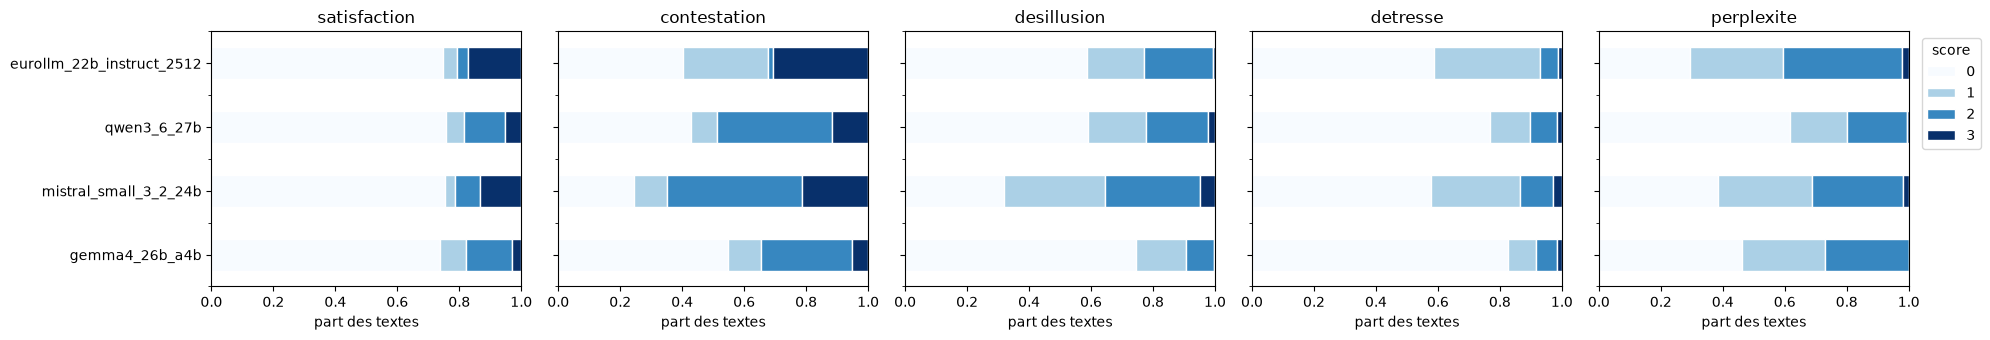

slug,eurollm_22b_instruct_2512,gemma4_26b_a4b,mistral_small_3_2_24b,qwen3_6_27b
dimension,,,,
contestation,1.23,0.85,1.62,1.18
desillusion,0.64,0.35,1.08,0.66
detresse,0.49,0.27,0.58,0.35
perplexite,1.13,0.81,0.95,0.59
satisfaction,0.63,0.47,0.59,0.48


In [37]:
dist = (
    long_df.dropna()
    .groupby(["dimension", "slug"])["score"]
    .value_counts(normalize=True)
    .unstack("score")
    .reindex(columns=[0, 1, 2, 3])
    .fillna(0)
)
fig, axes = plt.subplots(1, len(DIMENSIONS), figsize=(4 * len(DIMENSIONS), 3.5), sharey=True)
for ax, dim in zip(axes, DIMENSIONS):
    dist.loc[dim].reindex(available).plot.barh(stacked=True, ax=ax, colormap="Blues", legend=False, edgecolor="white")
    ax.set_title(dim)
    ax.set_xlim(0, 1)
    ax.set_xlabel("part des textes")
    ax.set_ylabel("")
axes[-1].legend(title="score", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(long_df.groupby(["dimension", "slug"])["score"].mean().unstack().round(2))

### Accord inter-modèles

- **α de Krippendorff ordinal** sur les 4 modèles, par dimension (> 0,8 : fiable ; 0,667–0,8 : acceptable pour des conclusions prudentes).
- **κ de Cohen pondéré quadratiquement** pour chaque paire de modèles.

In [38]:
def krippendorff_alpha_ordinal(data: np.ndarray, categories=(0, 1, 2, 3)) -> float:
    """data : tableau (annotateurs × items), NaN pour les valeurs manquantes."""
    cats = list(categories)
    k = len(cats)
    idx = {c: i for i, c in enumerate(cats)}
    o = np.zeros((k, k))  # matrice de coïncidences
    for col in data.T:
        vals = [idx[int(v)] for v in col if not np.isnan(v)]
        m = len(vals)
        if m < 2:
            continue
        counts = np.bincount(vals, minlength=k)
        o += (np.outer(counts, counts) - np.diag(counts)) / (m - 1)
    n_c = o.sum(axis=1)
    n = n_c.sum()
    # distance ordinale
    delta = np.zeros((k, k))
    for c in range(k):
        for d in range(k):
            lo, hi = min(c, d), max(c, d)
            delta[c, d] = (n_c[lo:hi + 1].sum() - (n_c[lo] + n_c[hi]) / 2) ** 2
    d_o = (o * delta).sum() / n
    d_e = (np.outer(n_c, n_c) * delta).sum() / (n * (n - 1))
    return 1 - d_o / d_e if d_e > 0 else np.nan


alpha = pd.Series({
    dim: krippendorff_alpha_ordinal(wide_df[dim].reindex(columns=available).to_numpy().T)
    for dim in DIMENSIONS
}, name="alpha_ordinal")
display(alpha.round(3).to_frame())

,alpha_ordinal
satisfaction,0.936
contestation,0.722
desillusion,0.555
detresse,0.600
perplexite,0.619


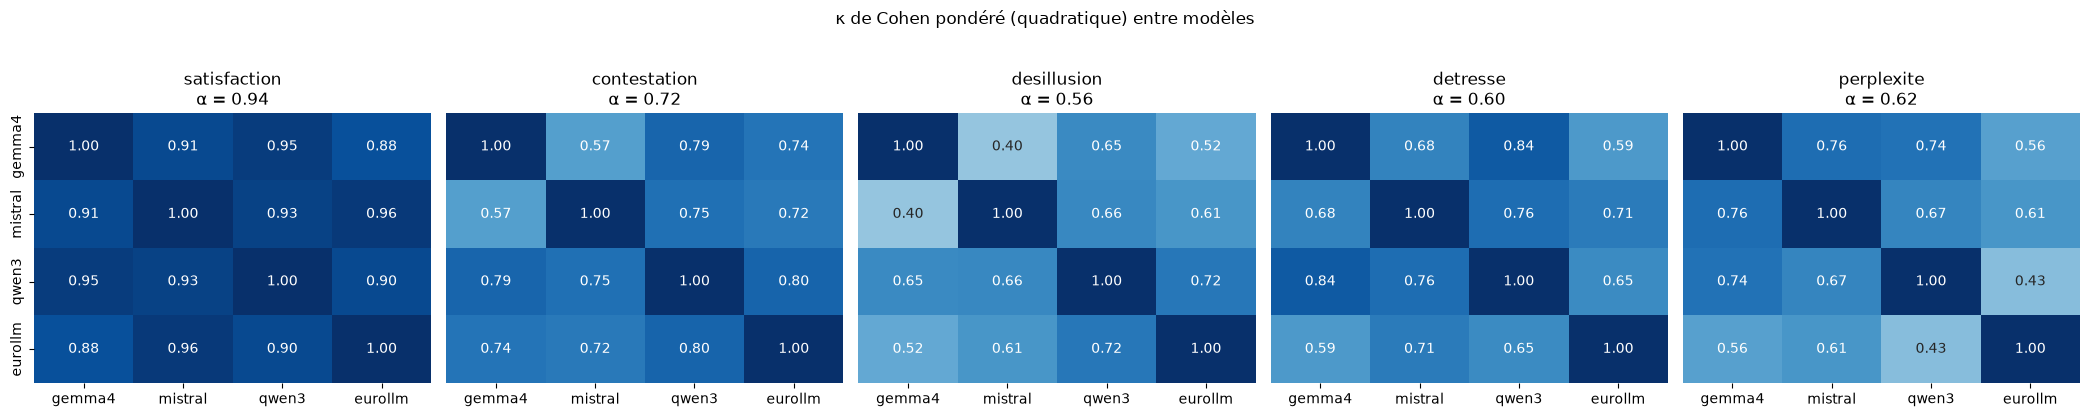

In [39]:
if len(available) >= 2:
    fig, axes = plt.subplots(1, len(DIMENSIONS), figsize=(4.2 * len(DIMENSIONS), 4))
    for ax, dim in zip(axes, DIMENSIONS):
        mat = pd.DataFrame(np.eye(len(available)), index=available, columns=available)
        for a, b in combinations(available, 2):
            pair = wide_df[dim][[a, b]].dropna()
            mat.loc[a, b] = mat.loc[b, a] = cohen_kappa_score(pair[a], pair[b], weights="quadratic")
        sns.heatmap(mat, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="Blues", cbar=False, ax=ax,
                    xticklabels=[s.split("_")[0] for s in available],
                    yticklabels=[s.split("_")[0] for s in available] if ax is axes[0] else False)
        ax.set_title(f"{dim}\nα = {alpha[dim]:.2f}")
    plt.suptitle("κ de Cohen pondéré (quadratique) entre modèles", y=1.03)
    plt.tight_layout()
    plt.show()

### Consensus

Score de consensus = **médiane** des modèles (arrondie à l'entier inférieur en cas d'égalité 2–2), avec l'écart max entre modèles
pour repérer les textes litigieux à relire.

In [40]:
consensus = pd.DataFrame(index=wide_df.index)
for dim in DIMENSIONS:
    scores = wide_df[dim].reindex(columns=available)
    consensus[dim] = np.floor(scores.median(axis=1))
    consensus[f"{dim}_ecart"] = scores.max(axis=1) - scores.min(axis=1)
    consensus[f"{dim}_n_modeles"] = scores.notna().sum(axis=1)
consensus = consensus.reset_index()
consensus.to_csv(OUT_DIR / "consensus.csv", index=False)

display(pd.DataFrame({
    "écart ≥ 2 (part des textes)": [(consensus[f"{d}_ecart"] >= 2).mean() for d in DIMENSIONS],
    "score consensus moyen": [consensus[d].mean() for d in DIMENSIONS],
}, index=DIMENSIONS).round(3))

,écart ≥ 2 (part des textes),score consensus moyen
satisfaction,0.023,0.480
contestation,0.255,1.053
desillusion,0.206,0.564
detresse,0.040,0.322
perplexite,0.194,0.731


In [41]:
# Textes les plus litigieux, à relire manuellement
ecarts = consensus[[f"{d}_ecart" for d in DIMENSIONS]].sum(axis=1)
litigieux = (
    consensus.assign(ecart_total=ecarts)
    .nlargest(10, "ecart_total")
    .merge(corpus_df, on="id_experience")
)
for _, row in litigieux.iterrows():
    print(f"--- {row['id_experience']} (écart total {row['ecart_total']:.0f})")
    print(row["full_comment"][:600])
    display(wide_df.loc[row["id_experience"]].unstack("slug").reindex(index=DIMENSIONS, columns=available))

--- 3954762 (écart total 10)
Attestation de chômage indemnisé régularisation de carrière

Bonjour , 

Même expérience , j'ai envoyé mon dossier à la CNAV IDF ( réceptionné le 20/02/2023 ) Ensuite silence radio , sur le site il est indiqué délai moyen 6 mois !!! Donc jusqu'au 20/08 et , toujours rien ,je relance , l'on me demande de patienter. Sauf que j'ai eu 62 ans en juillet, je ne suis donc plus indemnisé.
J'ai vraiment l'impression que l'on me pousse à la rue !


slug,gemma4_26b_a4b,mistral_small_3_2_24b,qwen3_6_27b,eurollm_22b_instruct_2512
dimension,,,,
satisfaction,0.0,0.0,0.0,0.0
contestation,0.0,2.0,2.0,3.0
desillusion,0.0,3.0,1.0,2.0
detresse,2.0,3.0,2.0,1.0
perplexite,0.0,0.0,0.0,2.0


--- 6824603 (écart total 10)
J'attends depuis 10 mois le 1er Paiement de l'AAEH

En janvier 25 , la Mdph du 94 a accordé une Aeeh pour mon fils né en 2013. Sur la notification il est indiqué " que le dossier est transmis automatiquement à la CAF de Créteil  , vous n'avez pas de démarches à faire".
En février 25 je reçois 1 mail de la CAF du 94  qui me demande de verser ma pièce d'identité sur mon compte CAF . La je découvre un vieux compte Caf ou rien n'est à jour et qui est clôturé (et inactif pour moi). J'envoie la pièce et j'attends .En avril 25 sans réponse je découvre que mon compte a été fermé car incomplet. Je fais


slug,gemma4_26b_a4b,mistral_small_3_2_24b,qwen3_6_27b,eurollm_22b_instruct_2512
dimension,,,,
satisfaction,0.0,0.0,0.0,0.0
contestation,0.0,2.0,0.0,1.0
desillusion,0.0,3.0,3.0,3.0
detresse,3.0,2.0,0.0,2.0
perplexite,2.0,1.0,0.0,2.0


--- 7057725 (écart total 10)
tres mauvaise expérience

bonjour,

j'ai  fait la rénovation extérieure  de ma maison  en AOUT 2025

Quand nous avons fait le dossier je devais récupérer une prime rénove que je n'est jamais reçus.

je me suis endetter pour 60 mois.

je suis veuf avec un petit salaire.


...

slug,gemma4_26b_a4b,mistral_small_3_2_24b,qwen3_6_27b,eurollm_22b_instruct_2512
dimension,,,,
satisfaction,0.0,0.0,0.0,0.0
contestation,0.0,2.0,0.0,1.0
desillusion,0.0,3.0,2.0,1.0
detresse,0.0,2.0,0.0,2.0
perplexite,0.0,1.0,0.0,2.0


--- 4845801 (écart total 9)
Bouton valider grisé!!!! Impossible de créer un télédéclarant

Bouton valider grisé. Impossible de créer un télédéclarant pour le registre de copropriété.

J'ai essayé sur plusieurs PC sur plusieurs navigateurs, supprimé les caches/ cookies etc.

Le site bug !


slug,gemma4_26b_a4b,mistral_small_3_2_24b,qwen3_6_27b,eurollm_22b_instruct_2512
dimension,,,,
satisfaction,0.0,0.0,0.0,0.0
contestation,0.0,3.0,2.0,0.0
desillusion,0.0,2.0,0.0,0.0
detresse,0.0,1.0,0.0,0.0
perplexite,1.0,2.0,0.0,3.0


--- 4852633 (écart total 9)
Tentative pour savoir si je suis inscrit pour voter

Une orgie de demandes de mots de passe et de codes pour finalement arriver dans une impasse. Impossible malgré tous les efforts de savoir si je suis inscrit ou pas. C’est une catastrophe.


slug,gemma4_26b_a4b,mistral_small_3_2_24b,qwen3_6_27b,eurollm_22b_instruct_2512
dimension,,,,
satisfaction,0.0,0.0,0.0,0.0
contestation,0.0,2.0,2.0,0.0
desillusion,1.0,3.0,2.0,0.0
detresse,0.0,1.0,1.0,0.0
perplexite,2.0,2.0,0.0,3.0


### Lien avec les Z-scores de l'analyse factorielle

Corrélations de Spearman entre le score de consensus LLM et les Z-scores de chaque dimension.
On attend une diagonale nettement plus forte que le reste de la matrice (validité convergente / discriminante).

Textes appariés : 10000


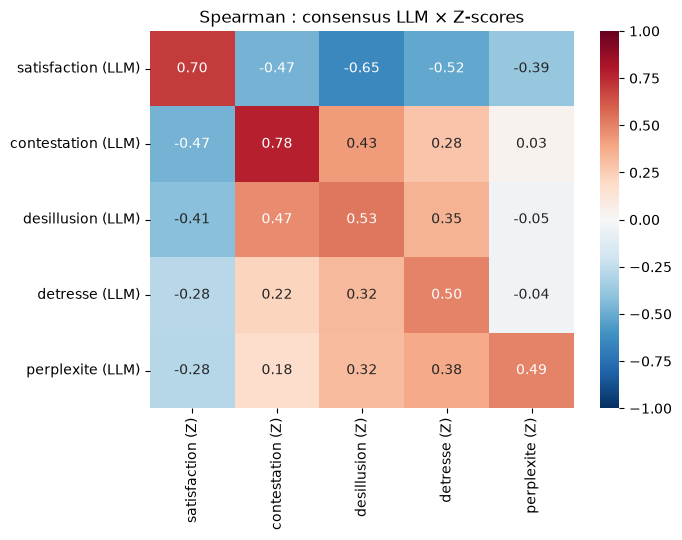

In [42]:
zscores_df = pd.read_csv(ZSCORES_PATH, encoding="utf-8-sig")
check = consensus[["id_experience", *DIMENSIONS]].merge(zscores_df, on="id_experience", suffixes=("_llm", "_z"))
print("Textes appariés :", len(check))

corr = pd.DataFrame(
    [[check[f"{a}_llm"].corr(check[f"{b}_z"], method="spearman") for b in DIMENSIONS] for a in DIMENSIONS],
    index=[f"{d} (LLM)" for d in DIMENSIONS],
    columns=[f"{d} (Z)" for d in DIMENSIONS],
)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Spearman : consensus LLM × Z-scores")
plt.tight_layout()
plt.show()